# B23 提问和原文用词不同，怎样找到相关内容？

任务：在同一份英文笔记和人工标签上，比较关键词检索与本地 MiniLM；用同语言对照避免把语言差异误当算法优势。

先修：B22；向量规范化、矩阵乘法与查询成本。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 固定笔记与同义改写问题
每个问题有一个提前指定的人工相关文档。模型从未看到本例标签，但预训练语料不可完全检查，因此不声称严格的新领域泛化。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer
import torch
torch.set_num_threads(2)
notes = [('D1', 'Cancel a laboratory booking at least four hours before it starts.'), ('D2', 'The library closes at ten in the evening on weekdays.'), ('D3', 'During heavy rain the outdoor event moves to the sports hall.'), ('D4', 'Report a broken bicycle and include its identification number.'), ('D5', 'Reimbursement requires an invoice and proof of payment.'), ('D6', 'Save random seeds and software versions before training a model.')]
questions = [('How do I withdraw my reservation?', 0), ('When must readers leave on Monday night?', 1), ('Where will people gather if it pours?', 2), ('What should I do about a damaged bike?', 3), ('Which receipts are needed to get my money back?', 4), ('What helps make an experiment repeatable?', 5)]
texts = [t for _, t in notes]
qs = [q for q, _ in questions]
gold = np.array([g for _, g in questions])
(DATA_DIR / 'semantic_notes.json').write_text(json.dumps({'notes': notes, 'questions': questions}, indent=2), encoding='utf-8')

1026

## 2. 关键词基线与零匹配
TF-IDF 只从当前笔记建立词表；完全没有共同词时所有分数可能为零，不能把排序返回的第一个文档算作有效命中。

In [3]:
v = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
lexical_matrix = v.fit_transform(texts)
t0 = time.perf_counter()
lexical_scores = (v.transform(qs) @ lexical_matrix.T).toarray()
lexical_seconds = time.perf_counter() - t0
lexical_top = lexical_scores.argmax(axis=1)
lexical_hit = (lexical_top == gold) & (lexical_scores.max(axis=1) > 0)

## 3. 本地向量编码与余弦相似度
normalize_embeddings=True 使向量长度为 1，矩阵乘法得到所有问题对所有笔记的相似度。分别记录模型加载、建索引和查询耗时，不用缓存后速度掩盖初次成本。

In [4]:
model_path = COURSE_ROOT / 'assets/models/minilm'
if not (model_path / 'config.json').is_file():
    raise FileNotFoundError(f'缺少嵌入模型：{model_path}')
t0 = time.perf_counter()
encoder = SentenceTransformer(str(model_path), device='cpu', local_files_only=True)
load_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
embeddings = encoder.encode(texts, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
index_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
query_embeddings = encoder.encode(qs, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)
semantic_scores = query_embeddings @ embeddings.T
query_seconds = time.perf_counter() - t0
semantic_top = semantic_scores.argmax(axis=1)
assert np.allclose(np.linalg.norm(embeddings, axis=1), 1, atol=1e-05)

## 4. 比较效果与成本
保留逐问题的预测来源，失败可回查。此处没有无答案阈值，语义相似度再高也不能替代相关性判断；中文任务需换成同语言评测集。

In [5]:
rows = [{'query': q, 'gold': notes[g][0], 'lexical_top': notes[int(a)][0], 'lexical_max_score': float(lexical_scores[i].max()), 'semantic_top': notes[int(b)][0], 'semantic_max_score': float(semantic_scores[i].max())} for i, ((q, g), a, b) in enumerate(zip(questions, lexical_top, semantic_top))]
(OUT_DIR / 'comparison.json').write_text(json.dumps(rows, indent=2), encoding='utf-8')
scores = [float(lexical_hit.mean()), float(np.mean(semantic_top == gold))]
barplot(['关键词', 'MiniLM 向量'], scores, '同义改写检索 Recall@1')
finish({'lexical_recall_at_1': scores[0], 'semantic_recall_at_1': scores[1], 'model_load_seconds': round(load_seconds, 3), 'index_seconds': round(index_seconds, 3), 'semantic_query_seconds': round(query_seconds, 3), 'lexical_query_seconds': round(lexical_seconds, 3), 'language': 'English controlled comparison'})

{
  "lexical_recall_at_1": 0.0,
  "semantic_recall_at_1": 1.0,
  "model_load_seconds": 0.129,
  "index_seconds": 0.056,
  "semantic_query_seconds": 0.035,
  "lexical_query_seconds": 0.001,
  "language": "English controlled comparison",
  "elapsed_seconds": 10.769
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

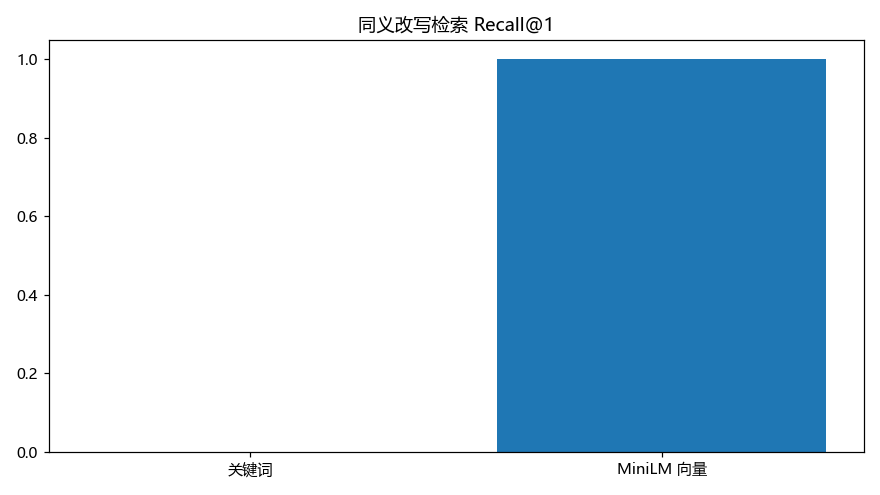

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
仅六个问题，不足以选定生产模型。中文模型与小候选重排为拓展；无关文本也会产生向量相似度。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。